# Logistic Regression

In our discussion of [maximum likelihood estimation](https://github.com/aecins/tutorials/blob/main/ml/maximum_likelihood_estimation.ipynb), we saw how to fit a parametric probabilistic model to data: we choose the parameters that minimize the negative log-likelihood (NLL) of the observed data, which brings the model close to the true [data-generating process](https://github.com/aecins/tutorials/blob/main/ml/data_generating_process.ipynb). We now apply this recipe to the simplest probabilistic classifier: **logistic regression**.

We proceed in steps. First, we define the logistic regression classifier and show that it is a parametric probabilistic model. Next, we fit it to labeled data with maximum likelihood estimation, and find that the resulting loss is the *binary cross-entropy*. Finally, we minimize this loss with gradient descent and implement the whole classifier from scratch in NumPy.

## The Task: Binary Classification

We return to our animal example, restricted to two species. Each sample consists of a feature vector $x \in \mathbb{R}^d$ and a label $y \in \{0, 1\}$, where $y = 1$ stands for "Dog" and $y = 0$ for "Cat". Our goal is a classifier, that is, a model of the conditional distribution $p^*(Y \mid X)$: the probability of each species given the features of an animal.

## The Logistic Regression Classifier

The logistic regression classifier takes a feature vector $x$ and computes a single number between 0 and 1 in two steps. First, it computes a linear function of the features, called the *score* or *logit*:

$$z = w^\top x + b$$

where $w \in \mathbb{R}^d$ is a vector of weights and $b \in \mathbb{R}$ is a bias. The score can take any real value, so in the second step it is passed through the **sigmoid function**, which squashes it into the interval $(0, 1)$:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

The output of the classifier is therefore:

$$\mu_\theta(x) = \sigma(w^\top x + b)$$

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

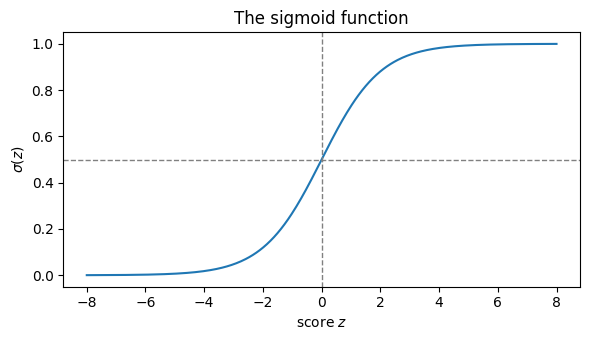

In [2]:
z = np.linspace(-8, 8, 400)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(z, 1 / (1 + np.exp(-z)))
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("The sigmoid function")
ax.set_xlabel(r"score $z$")
ax.set_ylabel(r"$\sigma(z)$")
plt.tight_layout()
plt.show()

Large negative scores give outputs close to 0, large positive scores give outputs close to 1, and a score of 0 gives an output of exactly 0.5.

### A Parametric Model

The form of the classifier, a linear score followed by a sigmoid, is fixed in advance. The weights and the bias are free: they are the **parameters** of the model, $\theta = (w, b)$, and every choice of their values gives a different classifier. In the terms of our discussion of maximum likelihood estimation, the formula $\sigma(w^\top x + b)$ defines a *model family*, and the parameters pick out one member of it. Learning means finding good values for $w$ and $b$.

### A Probabilistic Model

So far, the output $\mu_\theta(x)$ is just a number between 0 and 1. To turn the classifier into a probabilistic model, we interpret this number as the parameter of a probability distribution over the label.

The **Bernoulli distribution** is the distribution of a discrete random variable $Y$ that can take only two values, 0 and 1. It has a single parameter $\mu \in [0, 1]$, the probability that $Y = 1$. The probability that $Y = 1$ and $Y = 0$ is obtained as:

$$p(Y = 1) = \mu, \qquad p(Y = 0) = 1 - \mu$$

A classic example is a coin flip, with $Y = 1$ for heads and $\mu$ the probability of heads. Both cases can be written as a single formula:

$$p(y) = \mu^{y} \, (1 - \mu)^{1 - y}$$

For $y = 1$ the formula gives $\mu$, and for $y = 0$ it gives $1 - \mu$.

The Bernoulli distribution is the natural choice for our labels. A label can only be 0 ("Cat") or 1 ("Dog"), and as we saw in our discussion of the [data-generating process](https://github.com/aecins/tutorials/blob/main/ml/data_generating_process.ipynb), it is not necessarily determined by the features: the same features can belong to a cat or to a dog. For a given feature vector $x$, the label is therefore a random variable with two possible values, and every distribution over two values is a Bernoulli distribution.

We therefore interpret the output of the classifier as the Bernoulli parameter of the label, that is, as the predicted probability of "Dog". The predicted probabilities of the two classes are:

$$p_\theta(Y = 1 \mid x) = \mu_\theta(x), \qquad p_\theta(Y = 0 \mid x) = 1 - \mu_\theta(x)$$

or, in the compact form:

$$p_\theta(y \mid x) = \mu_\theta(x)^{y} \, \big(1 - \mu_\theta(x)\big)^{1 - y}$$

Under this interpretation, logistic regression is a parametric model of the conditional distribution $p^*(Y \mid X)$, exactly the kind of model to which maximum likelihood estimation applies.

## Fitting the Model with Maximum Likelihood

Now that we have a model, we want to choose its parameters so that it fits our data. Our dataset $\mathcal{D} = \{(x_1, y_1), \dots, (x_N, y_N)\}$ consists of feature vectors together with their class *labels*. Note that the dataset contains labels, not probabilities: we never observe the true probability $p^*(Y = 1 \mid x_i)$, only which species each animal actually was.

Because logistic regression is a parametric probabilistic model, we can fit it with [maximum likelihood estimation](https://github.com/aecins/tutorials/blob/main/ml/maximum_likelihood_estimation.ipynb): we choose the parameters under which the observed labels are most probable.

### The Likelihood of a Classifier

A classifier represents the conditional distribution $p_\theta(y \mid x)$, so its likelihood is the probability of the observed labels given the observed feature vectors. Since the samples are drawn i.i.d., this is a product over the samples:

$$L(\theta) = \prod_{i=1}^N p_\theta(y_i \mid x_i)$$

where:

* $x_i$ is the feature vector of the $i$-th sample in the dataset.
* $y_i$ is the observed label of the $i$-th sample in the dataset.
* $p_\theta(y_i \mid x_i)$ is the probability that the model assigns to the observed label $y_i$. For each feature vector, the model predicts a distribution over both labels, and this term picks out the probability of the correct one.

The likelihood is therefore the product, over all samples, of the probabilities that the model assigns to the correct labels.

### The Likelihood of Logistic Regression

Let $\mu_i = \mu_\theta(x_i) = \sigma(w^\top x_i + b)$ be the predicted probability of "Dog" for sample $i$. Plugging it in the Bernoulli formula, we get the likelihood in terms of the true labels and the predicted probabilities:

$$L(\theta) = \prod_{i=1}^N \mu_i^{y_i} \, (1 - \mu_i)^{1 - y_i}$$

This is where the compact form of the Bernoulli distribution pays off: the true label $y_i$ in the exponent selects which predicted probability enters the likelihood. For a dog ($y_i = 1$), the factor is $\mu_i$; for a cat ($y_i = 0$), it is $1 - \mu_i$. In both cases, it is the probability that the model assigns to the *correct* label.

### The Negative Log-Likelihood

As in our discussion of maximum likelihood estimation, we take the logarithm, average over the dataset and flip the sign. This gives the negative log-likelihood:

$$\text{NLL}(\theta) = -\frac{1}{N} \sum_{i=1}^N \Big[ y_i \log \mu_i + (1 - y_i) \log (1 - \mu_i) \Big]$$

For each sample, only one of the two terms is active: for a dog the cost is $-\log \mu_i$, and for a cat it is $-\log(1 - \mu_i)$, the negative log of the probability assigned to the correct label.

### Binary Cross-Entropy

The NLL above is known as the **binary cross-entropy loss**. The name comes from the fact that each term is a cross-entropy between two distributions over the labels $\{0, 1\}$: the true label of sample $i$, written as a distribution $q_i$ that puts all of its probability on $y_i$, and the predicted class probabilities $p_\theta(y \mid x_i)$:

$$H\big(q_i, p_\theta(\cdot \mid x_i)\big) = -\sum_{y \in \{0, 1\}} q_i(y) \log p_\theta(y \mid x_i) = -\Big[ y_i \log \mu_i + (1 - y_i) \log (1 - \mu_i) \Big]$$

We have therefore derived that **minimizing the binary cross-entropy between the predicted class probabilities and the true labels is exactly maximum likelihood estimation for logistic regression.** Other loss functions could also be used to train a classifier, but they do not correspond to maximum likelihood estimation for this model. The binary cross-entropy inherits the justification of maximum likelihood estimation: minimizing it brings the predicted probabilities close to the true conditional distribution $p^*(Y \mid X)$.

To minimize the binary cross-entropy, we need its gradient with respect to the parameters $w$ and $b$, which we derive next.

## Deriving the Gradient

To minimize $\text{NLL}(\theta)$ with gradient descent, we need its gradient with respect to the parameters $\theta = (w, b)$. It consists of two parts: the gradient with respect to the weights, $\nabla_w \text{NLL}$, and the derivative with respect to the bias, $\frac{\partial \text{NLL}}{\partial b}$.

The NLL is an average of per-sample losses $\ell_i$, and the gradient of an average is the average of the gradients: $\nabla_\theta \text{NLL}(\theta) = \frac{1}{N} \sum_{i=1}^N \nabla_\theta \ell_i(\theta)$. Since all per-sample losses have the same form, we only need to differentiate the loss of a single sample:

$$\ell_i = -\Big[ y_i \log \mu_i + (1 - y_i) \log (1 - \mu_i) \Big], \qquad \mu_i = \sigma(z_i), \qquad z_i = w^\top x_i + b$$

The loss depends on the parameters through a chain of three steps: the parameters determine the logit $z_i$, the logit determines the predicted probability $\mu_i$, and the predicted probability determines the loss $\ell_i$. By the chain rule, the gradient is therefore a product of three factors:

$$\nabla_w \ell_i = \frac{\partial \ell_i}{\partial \mu_i} \cdot \frac{\partial \mu_i}{\partial z_i} \cdot \nabla_w z_i, \qquad \frac{\partial \ell_i}{\partial b} = \frac{\partial \ell_i}{\partial \mu_i} \cdot \frac{\partial \mu_i}{\partial z_i} \cdot \frac{\partial z_i}{\partial b}$$

We compute the three factors one at a time.

1. **The loss with respect to the predicted probability:**

   $$
   \begin{aligned}
   \frac{\partial \ell_i}{\partial \mu_i} &= -\frac{y_i}{\mu_i} + \frac{1 - y_i}{1 - \mu_i} \\
   &= \frac{-y_i (1 - \mu_i) + (1 - y_i) \mu_i}{\mu_i (1 - \mu_i)} \\
   &= \frac{\mu_i - y_i}{\mu_i (1 - \mu_i)}
   \end{aligned}
   $$

2. **The predicted probability with respect to the logit.** This is the derivative of the sigmoid, which has a particularly convenient form:

   $$
   \begin{aligned}
   \sigma'(z) &= \frac{e^{-z}}{(1 + e^{-z})^2} \\
   &= \frac{1}{1 + e^{-z}} \cdot \frac{e^{-z}}{1 + e^{-z}} \\
   &= \sigma(z) \, \big(1 - \sigma(z)\big)
   \end{aligned}
   $$

   The derivative of the sigmoid can be expressed in terms of the sigmoid itself. For our sample, this gives:

   $$\frac{\partial \mu_i}{\partial z_i} = \sigma'(z_i) = \sigma(z) \, \big(1 - \sigma(z)\big) = \mu_i (1 - \mu_i)$$

3. **The logit with respect to the parameters:**

   $$\nabla_w z_i = x_i, \qquad \frac{\partial z_i}{\partial b} = 1$$

Multiplying the first two factors, the term $\mu_i (1 - \mu_i)$ cancels, and we are left with a remarkably simple expression:

$$\frac{\partial \ell_i}{\partial z_i} = \frac{\mu_i - y_i}{\mu_i (1 - \mu_i)} \cdot \mu_i (1 - \mu_i) = \mu_i - y_i$$

The derivative of the loss with respect to the logit is just the **prediction error**: the predicted probability of "Dog" minus the true label. Multiplying by the third factor gives the gradient for a single sample:

$$\nabla_w \ell_i = (\mu_i - y_i) \, x_i, \qquad \frac{\partial \ell_i}{\partial b} = \mu_i - y_i$$

Averaging over the dataset gives the gradient of the NLL:

$$\nabla_w \text{NLL}(\theta) = \frac{1}{N} \sum_{i=1}^N (\mu_i - y_i) \, x_i, \qquad \frac{\partial \text{NLL}(\theta)}{\partial b} = \frac{1}{N} \sum_{i=1}^N (\mu_i - y_i)$$

If we stack the feature vectors as the rows of a matrix $X \in \mathbb{R}^{N \times d}$, and the predicted probabilities and labels into vectors $\mu, y \in \mathbb{R}^N$, the gradient with respect to the weights becomes a single matrix product:

$$\nabla_w \text{NLL}(\theta) = \frac{1}{N} X^\top (\mu - y)$$

The gradient has an intuitive interpretation. Each sample pushes the weights in the direction of its own feature vector, scaled by its prediction error. Samples that the model already classifies correctly and confidently ($\mu_i \approx y_i$) barely contribute, while samples with large errors dominate the update.

### No Closed-Form Solution

Setting the gradient to zero gives the condition

$$\sum_{i=1}^N \big( \sigma(w^\top x_i + b) - y_i \big) \, x_i = 0$$

Because the parameters appear inside the nonlinear sigmoid, this equation cannot be solved for $w$ and $b$ analytically. We therefore have to find the minimum iteratively, with gradient descent. Fortunately, the NLL of logistic regression is a **convex** function of $\theta$: every local minimum is also the global one, so gradient descent with a suitable learning rate finds the best parameters (as long as a minimum exists).

## Training with Gradient Descent

Gradient descent minimizes the NLL by repeatedly taking small steps against the gradient:

$$w \leftarrow w - \eta \, \nabla_w \text{NLL}(\theta), \qquad b \leftarrow b - \eta \, \frac{\partial \text{NLL}(\theta)}{\partial b}$$

where $\eta$ is the learning rate. Our dataset is small, so we use **full-batch gradient descent**: every step computes the gradient on the entire dataset.

For large datasets, computing the full gradient for every step becomes too expensive. As we saw in our discussion of [maximum likelihood estimation](https://github.com/aecins/tutorials/blob/main/ml/maximum_likelihood_estimation.ipynb), the NLL decomposes into per-sample terms, so the gradient can instead be estimated from a small random **mini-batch** of samples at every step. This is how neural networks are trained in practice.

## Implementation in NumPy

### The Dataset

We generate a synthetic dataset of cats and dogs, described by two features: shoulder height (in cm) and weight (in kg). Both features are drawn from log-normal distributions, which keeps them positive and gives them the skewed shape typical of animal sizes. The two species overlap: small dogs are about as tall and heavy as large cats, so no straight line can separate them perfectly.

Height and weight are measured on different scales. Gradient descent uses a single learning rate for all parameters, and it works best when all features have similar scales. We therefore **standardize** each feature to zero mean and unit standard deviation before training.

We use all samples for training. In practice, a trained model should also be evaluated on separate, held-out data, but here we focus on the derivation and the optimization.

In [132]:
def sample_animals(median_size, log_std, correlation, num_samples, rng):
    # Draw (height, weight) pairs whose logarithms are jointly Gaussian.
    cov = np.array([
        [log_std[0] ** 2, correlation * log_std[0] * log_std[1]],
        [correlation * log_std[0] * log_std[1], log_std[1] ** 2],
    ])
    return np.exp(rng.multivariate_normal(np.log(median_size), cov, size=num_samples))


rng = np.random.default_rng(seed=0)
num_per_class = 300

cats = sample_animals(median_size=[25, 4.5], log_std=[0.12, 0.3], correlation=0.2, num_samples=num_per_class, rng=rng)
dogs = sample_animals(median_size=[36, 10], log_std=[0.2, 0.35], correlation=0.2, num_samples=num_per_class, rng=rng)

X = np.vstack([cats, dogs])
y = np.concatenate([np.zeros(num_per_class), np.ones(num_per_class)])

permutation = rng.permutation(len(y))
X, y = X[permutation], y[permutation]

# Standardize the features to zero mean and unit variance.
feature_mean = X.mean(axis=0)
feature_std = X.std(axis=0)

X = (X - feature_mean) / feature_std

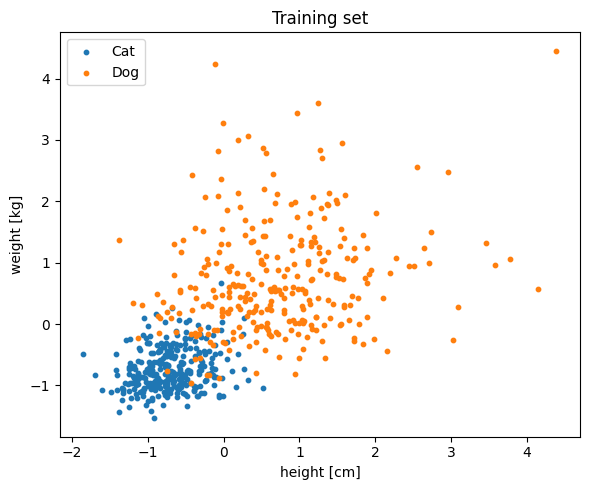

In [133]:
def plot_animals(ax, X, y):
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=10, label="Cat")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=10, label="Dog")
    ax.set_xlabel("height [cm]")
    ax.set_ylabel("weight [kg]")
    ax.legend()


fig, ax = plt.subplots(figsize=(6, 5))
plot_animals(ax, X * feature_std + feature_mean, y)
ax.set_title("Dataset")
plt.tight_layout()
plt.show()

### The Model and Its Gradient

The implementation follows the equations directly: `predict` computes $\mu_\theta(x) = \sigma(w^\top x + b)$, `loss` computes the binary cross-entropy, `gradient` computes the gradient we derived, and `fit` runs full-batch gradient descent.

**A note on numerical stability.** Implementing the formulas exactly as written works well for our standardized data, but it can fail when the score $z$ becomes large in magnitude:

* **The sigmoid can overflow.** For large negative $z$, the term $e^{-z}$ exceeds the largest representable floating-point number.
* **The loss can become infinite or undefined.** For large positive $z$, $\sigma(z)$ rounds to exactly 1 (in 64-bit floating point, this already happens around $z \approx 37$). Then $\log(1 - \mu_i) = \log 0 = -\infty$. Even for a correctly classified dog, the inactive term $(1 - y_i) \log(1 - \mu_i)$ becomes $0 \cdot (-\infty)$, which is `nan`.

The standard solution is to never compute the probability explicitly, and to compute the loss directly from the score instead. Substituting $\mu_i = \sigma(z_i)$ and simplifying gives an equivalent form of the per-sample loss:

$$\ell_i = \log(1 + e^{z_i}) - y_i \, z_i$$

which can be evaluated without overflow (for example with `np.logaddexp(0, z)` for the first term). This is what deep learning frameworks do: PyTorch's `BCEWithLogitsLoss` takes the scores (*logits*) rather than probabilities as input for exactly this reason.

In [ ]:
class LogisticRegression():
    def __init__(self, in_channels, num_iterations, lr):
        self.in_channels = in_channels
        self.num_iterations = num_iterations
        self.lr = lr
        self.weights = None
        self.bias = None

    def loss(self, preds, y):
        """Calculate binary cross-entropy loss between predictions and GT classes.
        
        Args:
            preds: predicted probabilities of class 1
                shape: (B)
            y: ground truth labels
                shape: (B)
        
        Returns:
            binary cross entropy loss
                shape (,)
        """

        # - 1/n * sum((y_i * log(preds_i) + (1-y_i) * log(1 - preds_i)))
        loss = y * np.log(preds) + (1 - y) * np.log(1 - preds)
        loss = - np.mean(loss)

        return loss

    def gradient(self, X, y):
        """Calculate the gradient of loss with respect to weights and bias.
        
            X: input features
                shape: (B, C)
            y: ground truth labels
                shape: (B)

        Returns:
            Gradient of weights
                shape: (C)
            Gradient of bias
                shape: (,)
        """

        # weights_grad = 1/n sum (X^T (preds - y))
        preds = self.predict(X)
        weights_grad = np.transpose(X) @ (preds - y) / X.shape[0]

        # bias_grad = 1/n sum (preds - y)
        bias_grad = np.mean(preds - y)

        return weights_grad, bias_grad

    def predict(self, X):
        """Calculate predictions (probability of class 1)
        
        Args:
            X: input features
                shape: (B, C)

        Returns:
            Predicted probabilities of class 1
                shape: (B)        
        """

        # sigmoid(z)
        # z = X*w + b
        # sigmoid = 1 / (1 + e^-z)

        z = X @ self.weights + self.bias
        preds = 1 / (1 + np.exp(-z))

        return preds

    def fit(self, X, y):
        """Optimize model weights to fit the input dataset.
        
        Args:
            X: input features
                shape: (B, C)
            y: ground truth labels
                shape: (B)
        """

        assert(X.shape[1] == self.in_channels)
        assert(X.shape[0] == y.shape[0])

        # Initialize model parameters.
        self.weights = np.zeros(self.in_channels)
        self.bias = 0

        # Calculate initial loss.
        previous_pred = self.predict(X)
        previous_loss = self.loss(previous_pred, y)

        # Iterate over number of iterations
        loss_history = [previous_loss]
        for it_idx in range(self.num_iterations):
            # Calculate gradient
            weights_grad, bias_grad = self.gradient(X, y)

            # Update model parameters
            self.weights -= weights_grad * self.lr
            self.bias -= bias_grad * self.lr

            # Calculate new loss
            new_pred = self.predict(X)
            new_loss = self.loss(new_pred, y)

            loss_history.append(new_loss)

        return loss_history

### Checking the Gradient

Before we train, we verify the derived gradient numerically. For each parameter, we nudge it by a small amount $\varepsilon$ in both directions and approximate the derivative with the *central finite difference*

$$\frac{\partial\, \text{NLL}}{\partial \theta_k} \approx \frac{\text{NLL}(\theta + \varepsilon e_k) - \text{NLL}(\theta - \varepsilon e_k)}{2 \varepsilon}$$

where $e_k$ is the unit vector for parameter $k$. If the derivation and the implementation are correct, the analytic and numerical gradients agree up to tiny numerical differences.

In [136]:
def logistic_regression_loss(X, y, logistic_regression):
    preds = logistic_regression.predict(X)
    loss = logistic_regression.loss(preds, y)

    return loss


def numerical_gradient(X, y, logistic_regression, eps=1e-3):
    """Calculates the gradients of the logistic regression parameters numerically, using central finite differences.
    
    Args:
        X: input features
            shape: (B, C)
        y: ground truth labels
            shape: (B)
        logistic_regression: LogisticRegression object. Used to access weights as well as calculate predictions and loss.

    Returns:
        Gradient of weights
            shape: (C)
        Gradient of bias
            shape: (,)
    """

    C = logistic_regression.in_channels

    # Gradient with respect to weights
    weights_original = logistic_regression.weights
    weights_grad = np.zeros(C)
    for channel in range(C):
        weight_delta = np.zeros(C)
        weight_delta[channel] = eps

        logistic_regression.weights = weights_original + weight_delta
        loss_plus = logistic_regression_loss(X, y, logistic_regression)

        logistic_regression.weights = weights_original - weight_delta
        loss_minus = logistic_regression_loss(X, y, logistic_regression)

        weights_grad[channel] = (loss_plus - loss_minus) / (2*eps)

    logistic_regression.weights = weights_original

    # Gradient with respect to bias
    bias_original = logistic_regression.bias
    logistic_regression.bias = bias_original + eps
    loss_plus = logistic_regression_loss(X, y, logistic_regression)

    logistic_regression.bias = bias_original - eps
    loss_minus = logistic_regression_loss(X, y, logistic_regression)

    bias_grad = (loss_plus - loss_minus) / (2 * eps)

    logistic_regression.bias = bias_original

    return weights_grad, bias_grad

# Test difference between analytical and numerical gradients on the training data
in_channels = X.shape[1]
num_iterations = 100
lr = 0.5
logistic_regression = LogisticRegression(in_channels, num_iterations, lr)
logistic_regression.weights = np.ones(in_channels)
logistic_regression.bias = -1

weights_grad_analytical, bias_grad_analytical = logistic_regression.gradient(X, y)
weights_grad_numerical, bias_grad_numerical = numerical_gradient(X, y, logistic_regression)


print("Weights grad analytical :", weights_grad_analytical)
print("Weights grad numerical  :", weights_grad_numerical)
print("Difference              :", weights_grad_analytical - weights_grad_numerical)

print("Bias grad analytical:", bias_grad_analytical)
print("Bias grad numerical :", bias_grad_numerical)
print("Difference          :", bias_grad_analytical - bias_grad_numerical)


Weights grad analytical : [-0.09360817 -0.10163271]
Weights grad numerical  : [-0.09360818 -0.10163273]
Difference              : [1.33205803e-08 1.52486229e-08]
Bias grad analytical: -0.16917141066758182
Bias grad numerical : -0.16917140654762464
Difference          : -4.119957180970246e-09


### Training

We now train the classifier with full-batch gradient descent, starting from all parameters set to zero, and record the loss after every iteration.

Learned parameters: w = [3.11354644 4.51590632] b = 1.6168662741042823


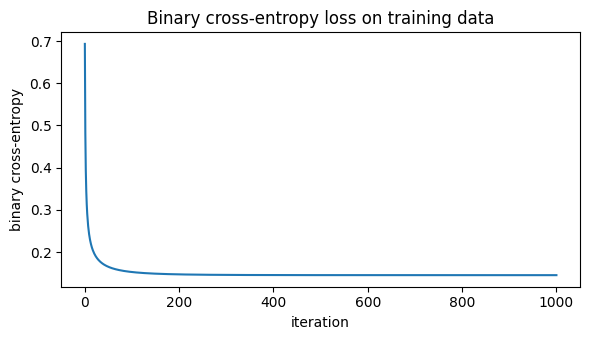

In [143]:
in_channels = X.shape[1]
num_iterations = 1000
lr = 1.0
logistic_regression = LogisticRegression(in_channels, num_iterations, lr)
loss_history = logistic_regression.fit(X, y)

print("Learned parameters: w =", logistic_regression.weights, "b =", logistic_regression.bias)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(loss_history)
ax.set_title("Binary cross-entropy loss on training data")
ax.set_xlabel("iteration")
ax.set_ylabel("binary cross-entropy")
plt.tight_layout()
plt.show()


The loss drops quickly in the first iterations and then levels off as the parameters approach the minimum.

### Results

To measure how often the classifier is right, we predict "Dog" whenever the predicted probability exceeds 0.5 and compare with the true labels:

In [ ]:
accuracy = np.mean((logistic_regression.predict(X) > 0.5) == y)
print(f"Accuracy: {accuracy:.1%}")

## Summary

* The logistic regression classifier computes $\mu_\theta(x) = \sigma(w^\top x + b)$. It is a **parametric** model with parameters $\theta = (w, b)$, and a **probabilistic** model: we interpret its output as the parameter of a Bernoulli distribution over the label.
* Fitting it with **maximum likelihood estimation** gives the **binary cross-entropy loss** between the predicted class probabilities and the true labels: for each sample, the negative log of the probability assigned to the correct label.
* The gradient of the loss has a simple form: $\nabla_w \text{NLL}(\theta) = \frac{1}{N} X^\top (\mu - y)$, the prediction errors weighted by the feature vectors.
* There is no closed-form solution, but the loss is convex, so **gradient descent** reliably finds the best parameters. Since the classifier predicts "Dog" exactly when $w^\top x + b > 0$, it separates the classes with a straight line (a hyperplane in general), which makes it a **linear classifier**.